In [1]:
from google.colab import files
import cv2
import matplotlib.pyplot as plt
import numpy as np


In [5]:
# Envie as três imagens nesta ordem:
# 1 - Escura; 2 - Clara/saturada; 3 - Bem exposta
arquivo = files.upload()
nomes = list(arquivo.keys())

if len(nomes) < 3:
    raise ValueError('Envie exatamente três imagens.')

def ler_upload(nome):
    return cv2.imdecode(np.frombuffer(arquivo[nome], np.uint8), cv2.IMREAD_COLOR)

img_escura = ler_upload(nomes[0])
img_clara = ler_upload(nomes[1])
img_bem_exposta = ler_upload(nomes[2])

cinza_escura = cv2.cvtColor(img_escura, cv2.COLOR_BGR2GRAY)
cinza_clara = cv2.cvtColor(img_clara, cv2.COLOR_BGR2GRAY)
cinza_bem_exposta = cv2.cvtColor(img_bem_exposta, cv2.COLOR_BGR2GRAY)


Saving escura.jpeg to escura (1).jpeg
Saving saturada.jpeg to saturada.jpeg
Saving exposta.jpeg to exposta.jpeg


In [6]:
def calc_hist(img):
    img_vetor = img.ravel()
    hist_vetor = np.zeros(256)
    for px in img_vetor:
        hist_vetor[int(px)] += 1
    return hist_vetor

def corrigir_gamma(img, gamma):
    tabela = np.array([((i / 255.0) ** gamma) * 255 for i in range(256)]).astype('uint8')
    return cv2.LUT(img, tabela)

def expandir_contraste(img, L=0, H=255):
    if H <= L:
        raise ValueError('H deve ser maior que L.')
    resultado = (img.astype(np.float32) - L) * (255.0 / (H - L))
    return np.clip(resultado, 0, 255).astype(np.uint8)


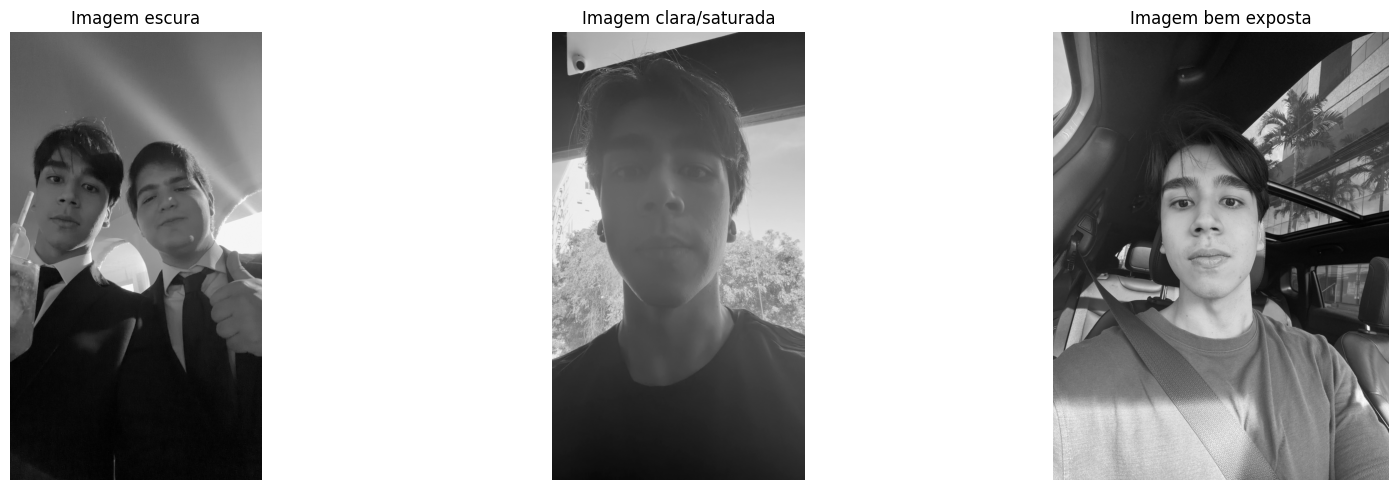

In [7]:
fig, eixos = plt.subplots(1, 3, figsize=(18, 5))
imagens = [cinza_escura, cinza_clara, cinza_bem_exposta]
titulos = ['Imagem escura', 'Imagem clara/saturada', 'Imagem bem exposta']

for eixo, img, titulo in zip(eixos, imagens, titulos):
    eixo.imshow(img, cmap='gray')
    eixo.set_title(titulo)
    eixo.axis('off')

plt.tight_layout()
plt.show()


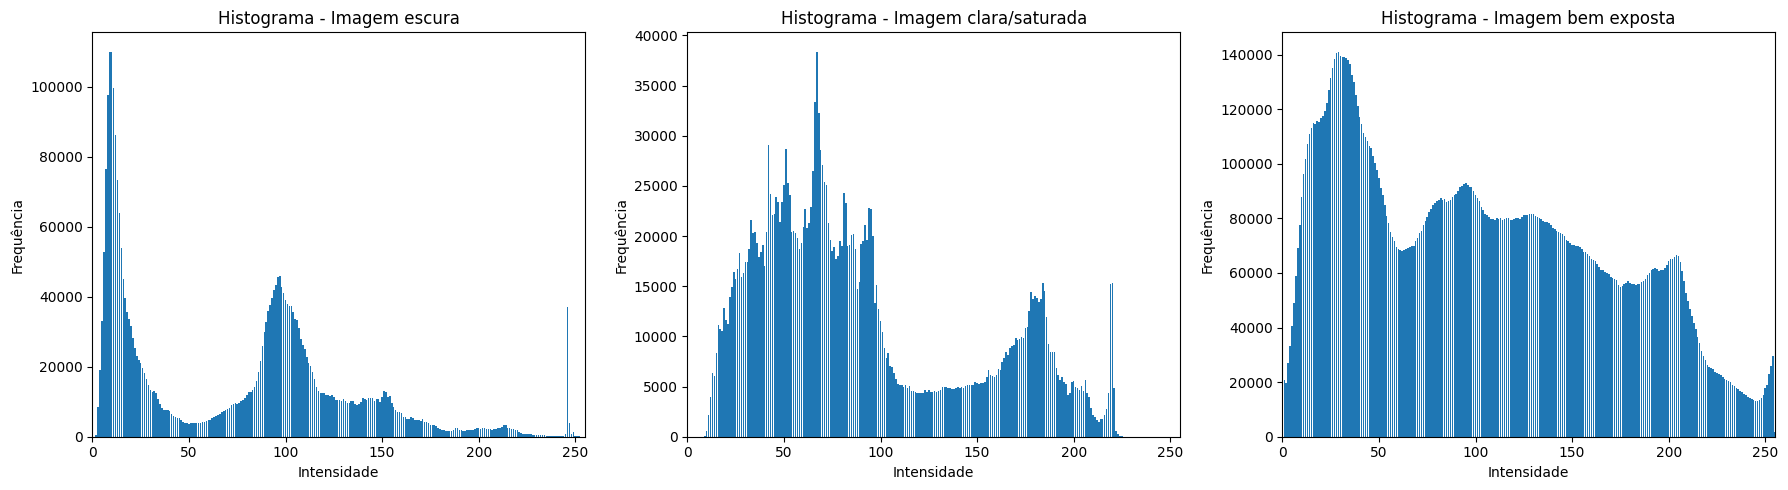

In [8]:
hist_escura = calc_hist(cinza_escura)
hist_clara = calc_hist(cinza_clara)
hist_bem_exposta = calc_hist(cinza_bem_exposta)

fig, eixos = plt.subplots(1, 3, figsize=(18, 5))
hists = [hist_escura, hist_clara, hist_bem_exposta]

for eixo, hist, titulo in zip(eixos, hists, titulos):
    eixo.bar(range(256), hist)
    eixo.set_title('Histograma - ' + titulo)
    eixo.set_xlabel('Intensidade')
    eixo.set_ylabel('Frequência')
    eixo.set_xlim([0, 255])

plt.tight_layout()
plt.show()


## Imagem 1 — Escura

O histograma apresenta maior concentração de pixels nas regiões de baixa intensidade, próximas do preto. Isso indica pouca luminosidade e concentração de detalhes nas sombras.

Foi escolhida a correção de gamma com γ = 0.5, pois valores menores que 1 clareiam a imagem e ajudam a revelar detalhes escuros.

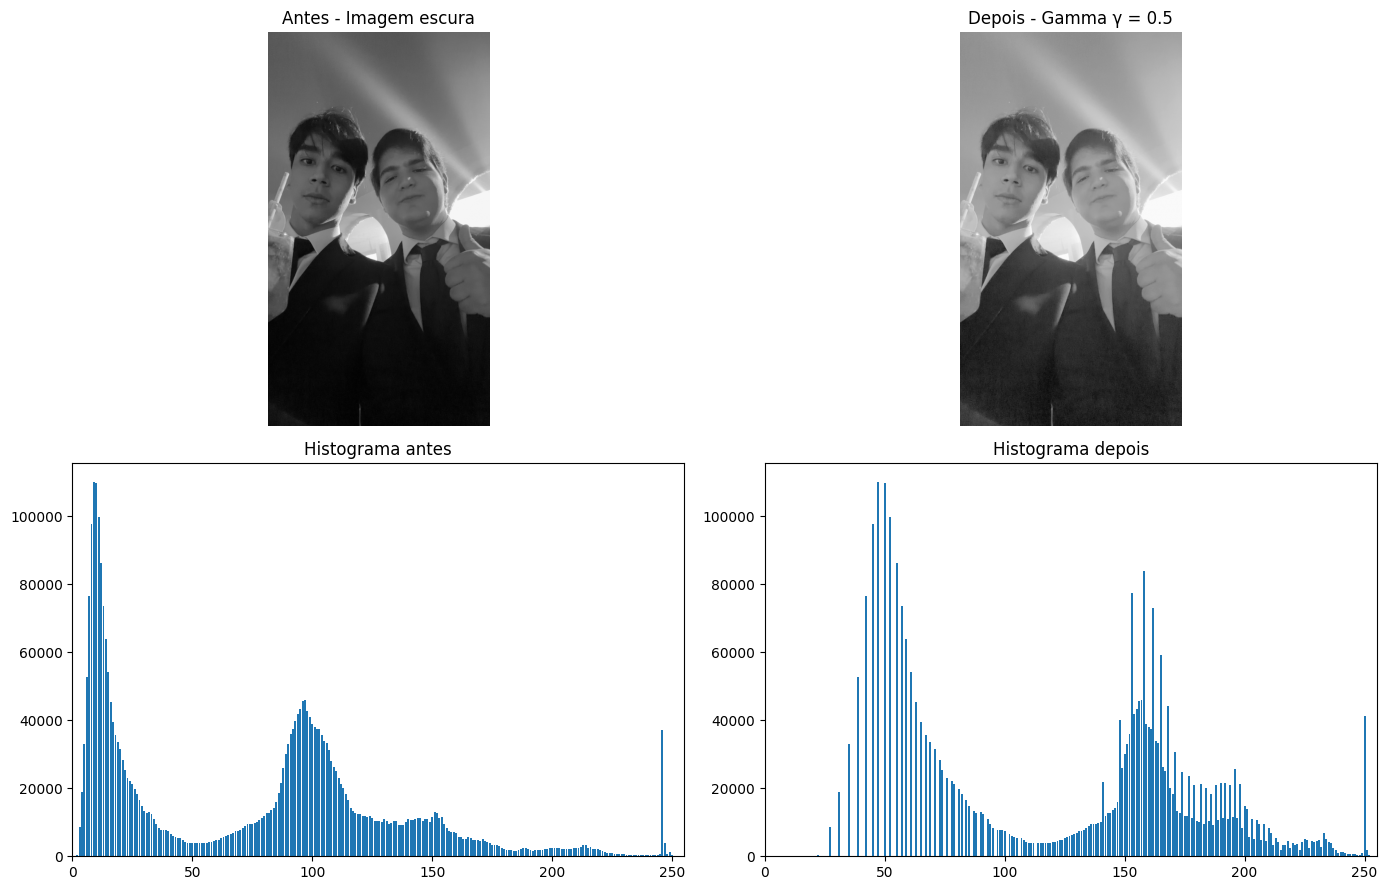

In [9]:
gamma_escura = 0.5
resultado_escura = corrigir_gamma(cinza_escura, gamma_escura)
hist_resultado_escura = calc_hist(resultado_escura)

fig, eixos = plt.subplots(2, 2, figsize=(14, 9))
eixos[0, 0].imshow(cinza_escura, cmap='gray'); eixos[0, 0].set_title('Antes - Imagem escura'); eixos[0, 0].axis('off')
eixos[0, 1].imshow(resultado_escura, cmap='gray'); eixos[0, 1].set_title('Depois - Gamma γ = 0.5'); eixos[0, 1].axis('off')
eixos[1, 0].bar(range(256), hist_escura); eixos[1, 0].set_title('Histograma antes'); eixos[1, 0].set_xlim([0, 255])
eixos[1, 1].bar(range(256), hist_resultado_escura); eixos[1, 1].set_title('Histograma depois'); eixos[1, 1].set_xlim([0, 255])
plt.tight_layout(); plt.show()


## Imagem 2 — Clara ou saturada

O histograma apresenta maior concentração de pixels nas regiões de alta intensidade, próximas do branco. Isso indica excesso de luminosidade e possível perda de detalhes nas áreas claras.

Foi escolhida a correção de gamma com γ = 2.0, pois valores maiores que 1 escurecem a imagem e reduzem o excesso de luminosidade.

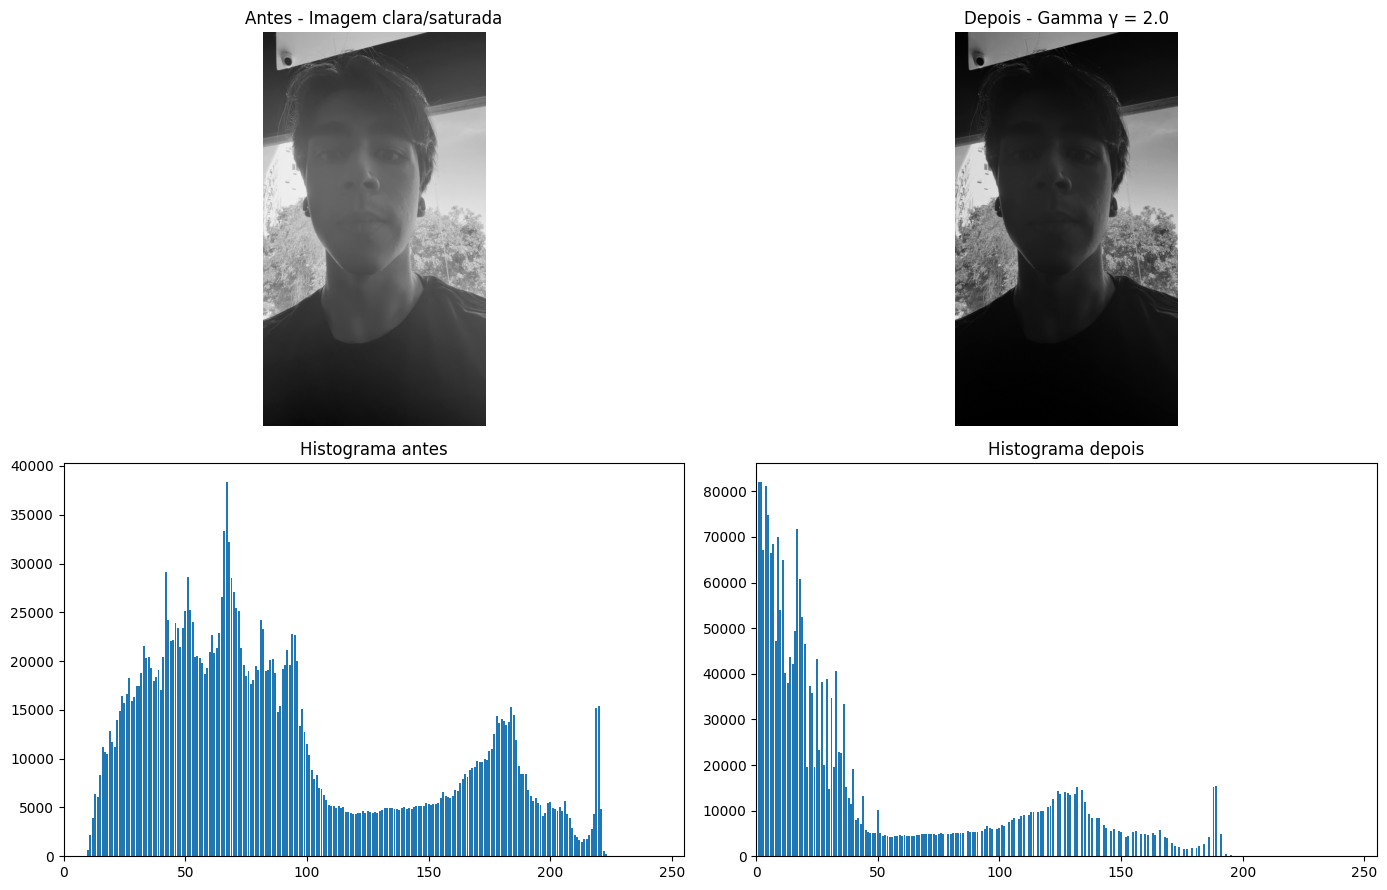

In [10]:
gamma_clara = 2.0
resultado_clara = corrigir_gamma(cinza_clara, gamma_clara)
hist_resultado_clara = calc_hist(resultado_clara)

fig, eixos = plt.subplots(2, 2, figsize=(14, 9))
eixos[0, 0].imshow(cinza_clara, cmap='gray'); eixos[0, 0].set_title('Antes - Imagem clara/saturada'); eixos[0, 0].axis('off')
eixos[0, 1].imshow(resultado_clara, cmap='gray'); eixos[0, 1].set_title('Depois - Gamma γ = 2.0'); eixos[0, 1].axis('off')
eixos[1, 0].bar(range(256), hist_clara); eixos[1, 0].set_title('Histograma antes'); eixos[1, 0].set_xlim([0, 255])
eixos[1, 1].bar(range(256), hist_resultado_clara); eixos[1, 1].set_title('Histograma depois'); eixos[1, 1].set_xlim([0, 255])
plt.tight_layout(); plt.show()


## Imagem 3 — Bem exposta

O histograma apresenta uma distribuição de intensidades mais equilibrada, com pixels distribuídos em diferentes faixas de luminosidade. Isso indica exposição adequada, com detalhes nas regiões escuras e claras.

Foi escolhida a expansão de contraste com L = 0 e H = 255. Como a imagem já apresenta boa distribuição de intensidades, espera-se uma alteração visual menor.

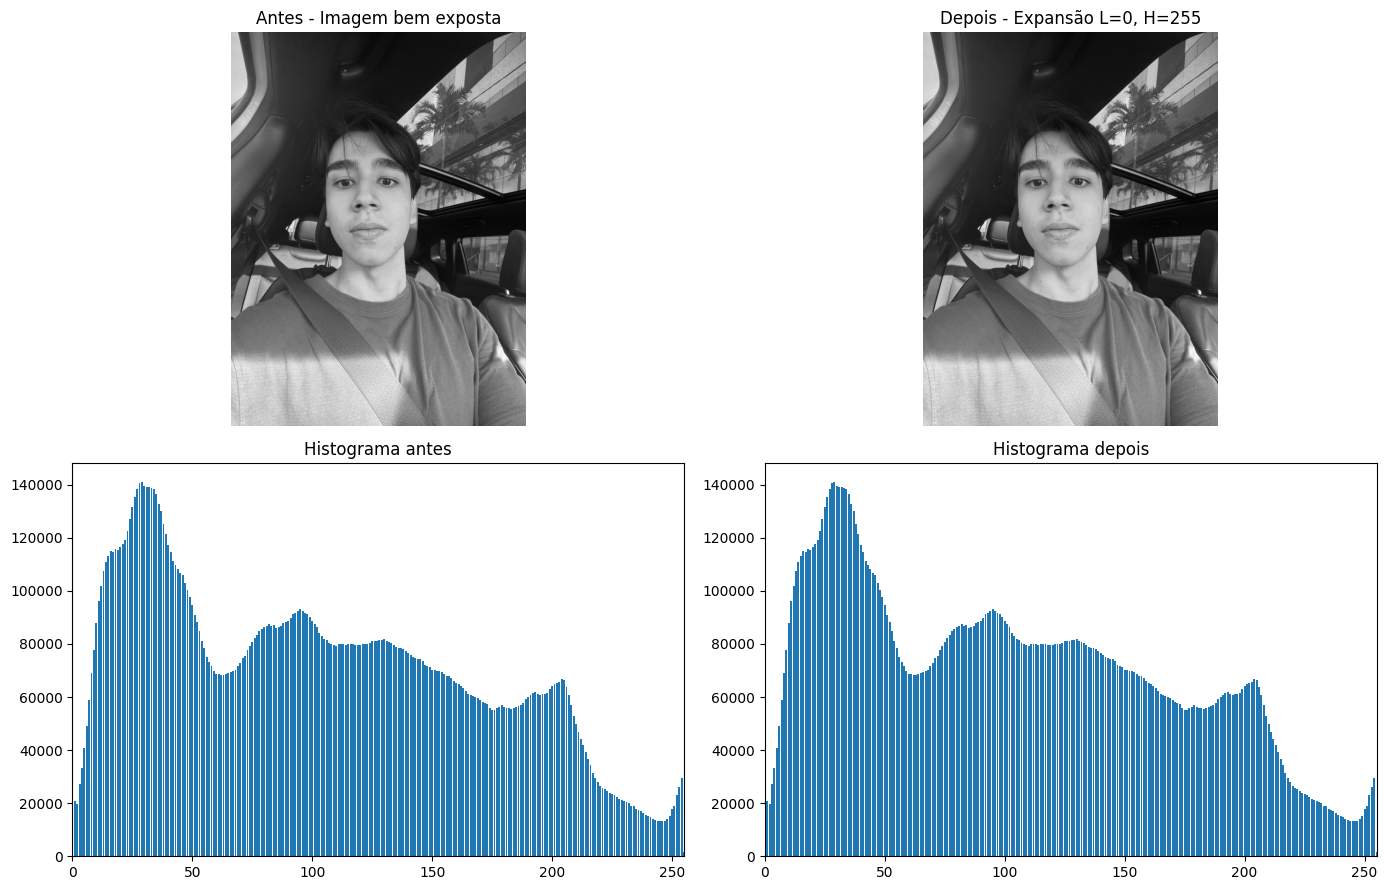

In [11]:
L_bem_exposta = 0
H_bem_exposta = 255
resultado_bem_exposta = expandir_contraste(cinza_bem_exposta, L_bem_exposta, H_bem_exposta)
hist_resultado_bem_exposta = calc_hist(resultado_bem_exposta)

fig, eixos = plt.subplots(2, 2, figsize=(14, 9))
eixos[0, 0].imshow(cinza_bem_exposta, cmap='gray'); eixos[0, 0].set_title('Antes - Imagem bem exposta'); eixos[0, 0].axis('off')
eixos[0, 1].imshow(resultado_bem_exposta, cmap='gray'); eixos[0, 1].set_title('Depois - Expansão L=0, H=255'); eixos[0, 1].axis('off')
eixos[1, 0].bar(range(256), hist_bem_exposta); eixos[1, 0].set_title('Histograma antes'); eixos[1, 0].set_xlim([0, 255])
eixos[1, 1].bar(range(256), hist_resultado_bem_exposta); eixos[1, 1].set_title('Histograma depois'); eixos[1, 1].set_xlim([0, 255])
plt.tight_layout(); plt.show()


## Conclusão

A imagem em que a operação fez menos diferença foi a imagem bem exposta. Isso ocorreu porque ela já apresentava uma distribuição de intensidades relativamente equilibrada, sem excesso significativo de regiões escuras ou claras. Assim, a expansão de contraste com L = 0 e H = 255 provocou uma alteração visual menor em comparação com as correções aplicadas nas imagens escura e clara, que possuíam problemas de exposição mais evidentes.